# Feature Extraction and Price Prediction for Mobile Phones

End-to-end project notebook: data exploration → preprocessing → feature extraction → feature selection → modelling → evaluation → feature importance.

**Key design choices** (explained in detail in the report): prices are in Indian rupees; models are evaluated both on a plain random split (as in the brief) and on a *leakage-safe* split that holds out whole phone models; Model and Colour are not used as predictors because they only let a model memorise specific phones.

Run the cells top to bottom. The dataset is read from `data/Flip_Data.xlsx` and charts are saved to `figures/`.

In [1]:
import json
import re
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.feature_selection import f_regression, mutual_info_regression
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore")
SEED = 42
ROOT = Path.cwd()
FIG = ROOT / "figures"
DATA = ROOT / "data"
FIG.mkdir(exist_ok=True)
DATA.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
PALETTE = "#2F5D8C"
RESULTS = {}


def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / name, dpi=150)
    plt.show()

## 1. Data exploration
Load the workbook, inspect types and missing values, then tidy the column names (the source has typos such as `Prize` and trailing underscores).

In [2]:
src = str(ROOT / "data" / "Flip_Data.xlsx")
raw = pd.read_excel(src, sheet_name=0)
RESULTS["raw_shape"] = list(raw.shape)
print("Raw shape:", raw.shape)
print(raw.dtypes)
print("Missing values:\n", raw.isna().sum())

# Tidy column names (the source has typos / trailing underscores)
df = raw.drop(columns=["Unnamed: 0"]).rename(columns={
    "Battery_": "Battery", "Rear Camera": "RearCamera", "Front Camera": "FrontCamera",
    "AI Lens": "AILens", "Mobile Height": "Height", "Processor_": "Processor", "Prize": "Price"})

Raw shape: (541, 12)
Unnamed: 0         int64
Model                str
Colour               str
Memory             int64
RAM                int64
Battery_           int64
Rear Camera          str
Front Camera         str
AI Lens            int64
Mobile Height    float64
Processor_           str
Prize              int64
dtype: object
Missing values:
 Unnamed: 0       0
Model            0
Colour           0
Memory           0
RAM              0
Battery_         0
Rear Camera      0
Front Camera     0
AI Lens          0
Mobile Height    0
Processor_       0
Prize            0
dtype: int64


## 2. Data preprocessing
Remove duplicates and non-smartphone rows, fix impossible values, parse camera strings, and extract Brand, chipset family/tier and a 5G flag from messy text.

In [3]:
log = {}

# 2a. Exact duplicate listings
n0 = len(df)
df = df.drop_duplicates().reset_index(drop=True)
log["exact_duplicates_removed"] = n0 - len(df)

# 2b. Text repair: mojibake characters in processor / colour strings
def fix_text(s):
    return re.sub(r"[^\x00-\x7F]+", " ", str(s)).strip()
for c in ["Model", "Colour", "Processor"]:
    df[c] = df[c].map(fix_text)

In [4]:
# 2c. Camera columns "50MP" -> 50 (numeric)
for c in ["RearCamera", "FrontCamera"]:
    df[c] = df[c].str.extract(r"(\d+)")[0].astype(float)

# 2d. Implausible listings: feature phones / mis-scraped rows (price < Rs 3,000 with
#     0-2MP cameras, <=1000 mAh batteries or screen height < 10 cm, or storage that does not
#     match the price band, e.g. "Micromax 256 GB for Rs 1,299").
mask_bad = df["Price"] < 3000
log["feature_phone_or_invalid_rows_removed"] = int(mask_bad.sum())
RESULTS["removed_examples"] = df.loc[mask_bad, ["Model", "Memory", "RAM", "Price"]].head(8).to_dict("records")
df = df[~mask_bad].reset_index(drop=True)

# 2e. Impossible handset height (41.94 cm for Moto G62) -> treat as missing
df["Height_was_outlier"] = (df["Height"] > 25) | (df["Height"] < 10)
log["height_outliers_set_missing"] = int(df["Height_was_outlier"].sum())
df.loc[df["Height_was_outlier"], "Height"] = np.nan

In [5]:
# 2f. Zero-megapixel cameras on a working smartphone are missing data, not a real 0
for c in ["RearCamera", "FrontCamera"]:
    log[f"{c}_zero_as_missing"] = int((df[c] == 0).sum())
    df.loc[df[c] == 0, c] = np.nan

# 2g. Brand extraction (inconsistent casing, sub-brands)
def brand_of(model):
    t = model.strip().lower()
    first = t.split()[0]
    if t.startswith("i kall"):
        return "I Kall"
    if first in ("redmi", "poco"):
        return "Xiaomi (Redmi/POCO)"
    if first.startswith("micromax"):
        return "Micromax"
    if first == "iqoo":
        return "iQOO"
    if first == "oneplus":
        return "OnePlus"
    if first in ("apple",):
        return "Apple"
    return first.capitalize() if first not in ("vivo", "oppo") else first.upper() if first == "oppo" else "vivo"
df["Brand"] = df["Model"].map(brand_of)
df["ModelKey"] = df["Model"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
# Fold spelling variants such as "micromax1", "narzo 50i prime" / "Narzo 50i Prime"
df["ModelKey"] = df["ModelKey"].str.replace("micromax1", "micromax 1")
rare = df["Brand"].value_counts()
rare = rare[rare < 8].index
df["Brand"] = df["Brand"].where(~df["Brand"].isin(rare), "Other")

In [6]:
# 2h. Processor text -> chipset family + performance tier (domain-knowledge mapping)
def chip_family(p, brand):
    s = p.lower()
    if "ios" in s or brand == "Apple":
        return "Apple"
    if "tensor" in s:
        return "Google Tensor"
    if "snapdragon" in s or "sm6" in s:
        return "Qualcomm Snapdragon"
    if "dimensity" in s or "mtk dimensity" in s:
        return "MediaTek Dimensity"
    if "helio" in s or re.search(r"\bg(25|35|36|37|70|80|85|88|95|96|99)\b", s) or "mt" in s[:4]:
        return "MediaTek Helio"
    if "exynos" in s or "s5e" in s:
        return "Samsung Exynos"
    if "unisoc" in s or "spreadtrum" in s or re.search(r"\bsc\d|\bt6\d\d|\bt7\d\d", s):
        return "Unisoc/Spreadtrum"
    return "Unknown"

TIER_RULES = [  # (regex, tier)   1 = entry ... 4 = flagship ; evaluated in order
    (r"snapdragon 8|snapdragon 7\+|snapdragon 888|snapdragon 865|snapdragon 855|snapdragon 845|tensor|dimensity 8|ios|apple", 4),
    (r"snapdragon 778|snapdragon 765|dimensity 9|dimensity 1[0-3]\d\d|dimensity 7200|exynos 1380", 3),
    (r"snapdragon 6|snapdragon 695|snapdragon 7[0-5]|snapdragon 720|snapdragon 730|dimensity 700|dimensity 6|dimensity 8[01]0"
     r"|dimensity 800|helio g(70|80|85|88|9\d)|exynos 1330|s5e8535|mtk dimensity|helio g88|g88|g96|g99|g85|g95", 2),
    (r"helio (a|p|g(25|35|36|37))|\bg(25|35|36|37)\b|unisoc|spreadtrum|sc9863|t6\d\d|t7\d\d|snapdragon 4|snapdragon 439"
     r"|exynos 850", 1),
]
def chip_tier(p):
    s = p.lower()
    for rx, t in TIER_RULES:
        if re.search(rx, s):
            return t
    return np.nan

df["ChipFamily"] = [chip_family(p, b) for p, b in zip(df["Processor"], df["Brand"])]
df["ChipTier"] = df["Processor"].map(chip_tier)
# Unknown / generic strings ("Octa Core", "MediaTek", "Android") -> tier of same model if known
df["ChipTier"] = df.groupby("ModelKey")["ChipTier"].transform(lambda s: s.fillna(s.median()))
log["chip_tier_unresolved_before_impute"] = int(df["ChipTier"].isna().sum())

In [7]:
# 2i. 5G flag and stand-alone numeric flags parsed from the model name
df["Is5G"] = df["Model"].str.contains(r"\b5g\b|\bgt 2\b|\bx5\b|\bf5\b|\bedge\b|\bnothing\b|\biphone\b|\bpixel\b", case=False, regex=True).astype(int)

# 2j. Missing numerics -> model median, then global median (done inside the pipeline for
#     modelling to avoid leakage; here we keep NaN and let SimpleImputer handle it).
df["PremiumBrand"] = df["Brand"].isin(["Apple", "Google", "OnePlus", "Nothing"]).astype(int)

RESULTS["cleaning_log"] = log
print("Cleaning log:", log)
print("Clean shape:", df.shape)

NUM = ["Memory", "RAM", "Battery", "RearCamera", "FrontCamera", "AILens", "Height", "ChipTier", "Is5G"]
CAT = ["Brand", "ChipFamily"]
TARGET = "Price"
df.to_csv(DATA / "cleaned_mobile_data.csv", index=False)

Cleaning log: {'exact_duplicates_removed': 10, 'feature_phone_or_invalid_rows_removed': 14, 'height_outliers_set_missing': 3, 'RearCamera_zero_as_missing': 0, 'FrontCamera_zero_as_missing': 1, 'chip_tier_unresolved_before_impute': 13}
Clean shape: (517, 18)


### Exploration plots on the cleaned data

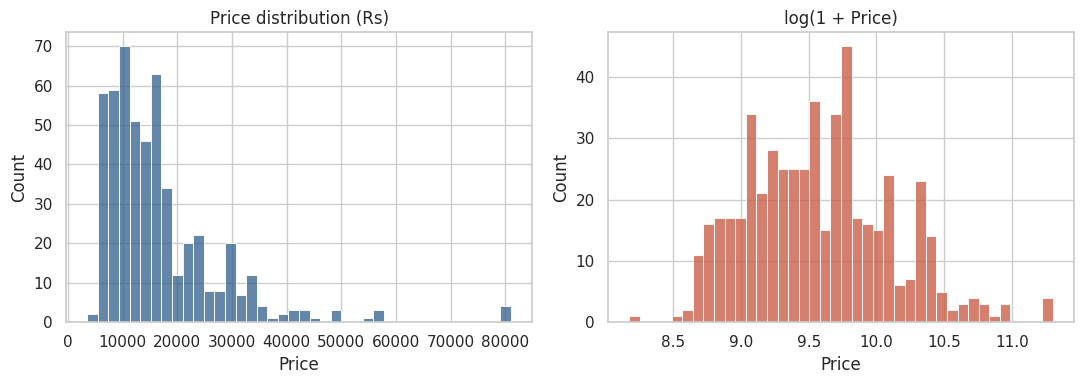

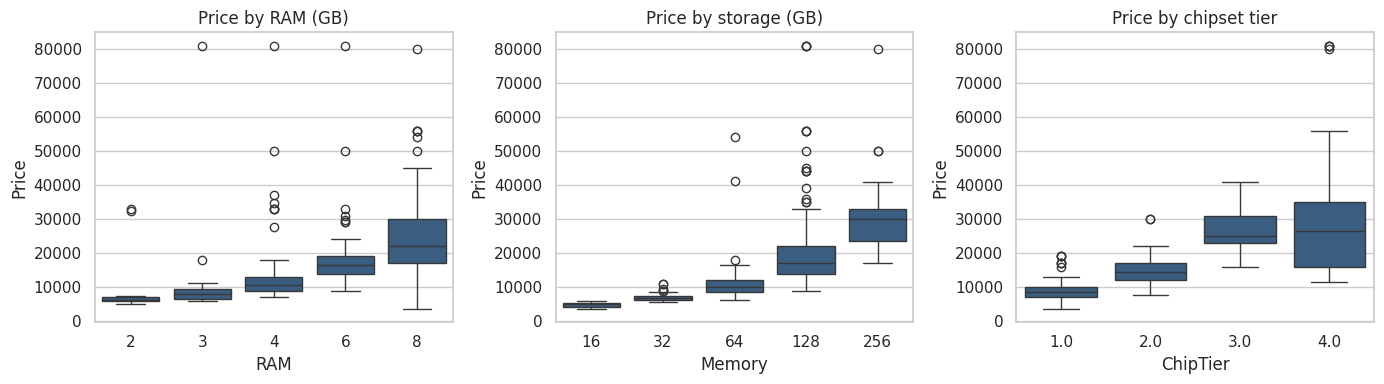

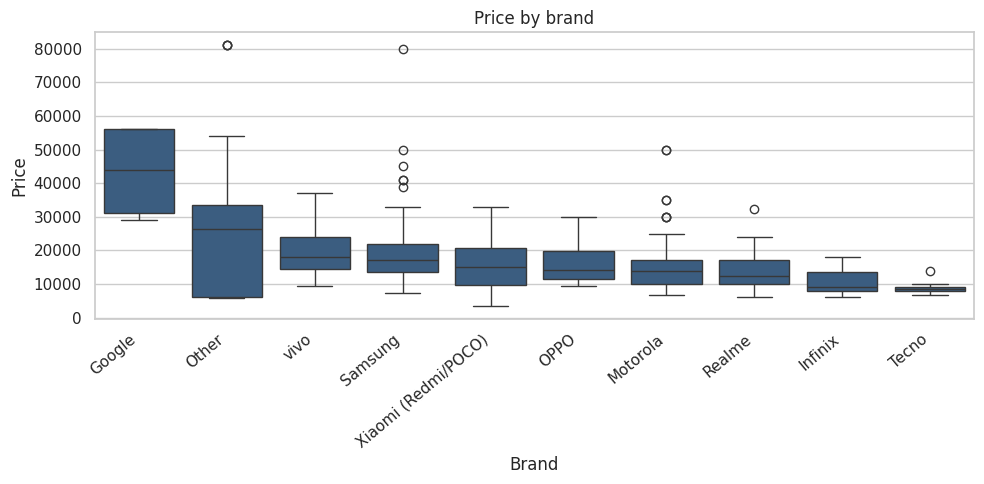

In [8]:
RESULTS["clean_shape"] = list(df.shape)
RESULTS["price_summary"] = df[TARGET].describe().round(0).to_dict()
RESULTS["n_models"] = int(df["ModelKey"].nunique())
RESULTS["brand_counts"] = df["Brand"].value_counts().to_dict()

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df[TARGET], bins=40, color=PALETTE, ax=ax[0]); ax[0].set_title("Price distribution (Rs)")
sns.histplot(np.log1p(df[TARGET]), bins=40, color="#C8553D", ax=ax[1]); ax[1].set_title("log(1 + Price)")
savefig("01_price_distribution.png")

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
sns.boxplot(data=df, x="RAM", y=TARGET, color=PALETTE, ax=ax[0]); ax[0].set_title("Price by RAM (GB)")
sns.boxplot(data=df, x="Memory", y=TARGET, color=PALETTE, ax=ax[1]); ax[1].set_title("Price by storage (GB)")
sns.boxplot(data=df, x="ChipTier", y=TARGET, color=PALETTE, ax=ax[2]); ax[2].set_title("Price by chipset tier")
savefig("02_price_by_ram_storage_chip.png")

order = df.groupby("Brand")[TARGET].median().sort_values(ascending=False).index
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="Brand", y=TARGET, order=order, color=PALETTE)
plt.xticks(rotation=40, ha="right"); plt.title("Price by brand")
savefig("03_price_by_brand.png")

## 3–4. Feature extraction and selection analysis
Spearman correlation, mutual information, ANOVA, a colour significance test, and PCA.

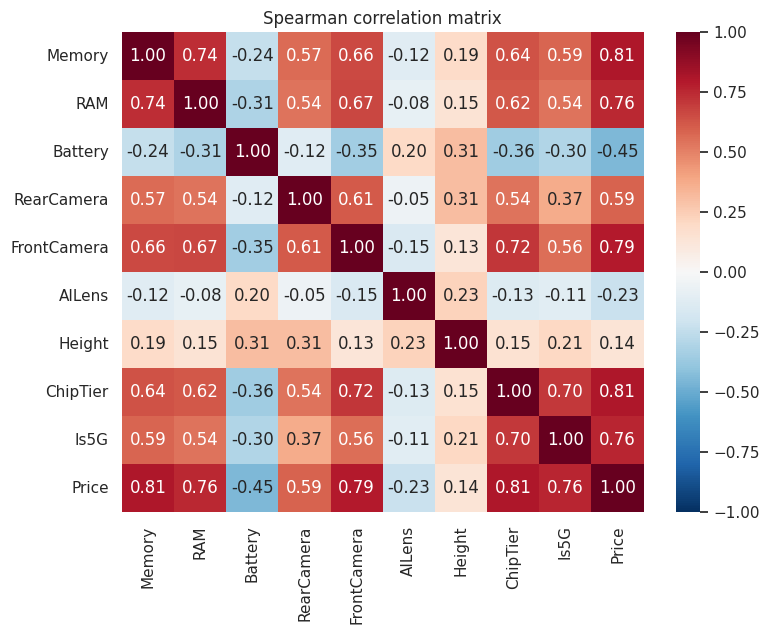

In [9]:
num_imp = df[NUM].copy()
num_imp = num_imp.fillna(num_imp.median())

# Pearson and Spearman correlation with price
corr = pd.DataFrame({
    "pearson": num_imp.corrwith(df[TARGET]),
    "spearman": num_imp.corrwith(df[TARGET], method="spearman")}).sort_values("spearman", ascending=False)
RESULTS["correlation"] = corr.round(3).to_dict("index")

plt.figure(figsize=(8, 6.5))
sns.heatmap(pd.concat([num_imp, df[TARGET]], axis=1).corr(method="spearman"), annot=True, fmt=".2f",
            cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Spearman correlation matrix")
savefig("04_correlation_heatmap.png")

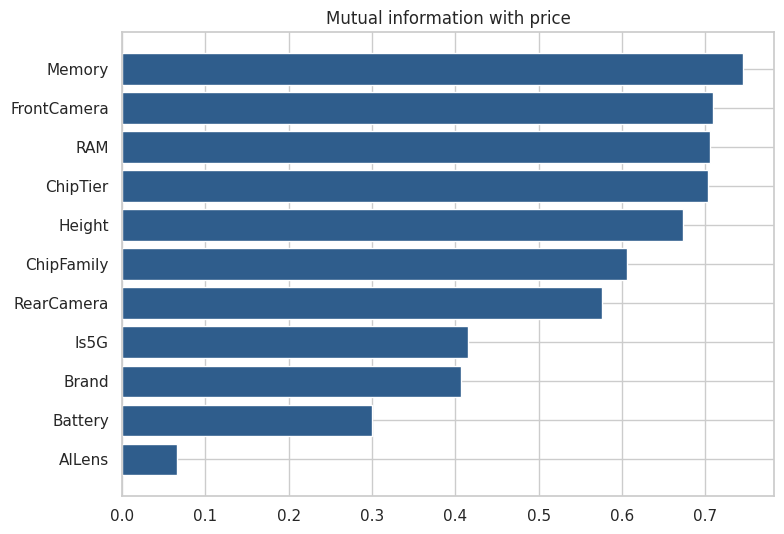

In [10]:
# Mutual information (categoricals kept as single discrete columns so scores are comparable)
# + ANOVA F-test on numeric features
X_mi = num_imp.copy()
for c in CAT:
    X_mi[c] = df[c].astype("category").cat.codes
disc = [c in CAT for c in X_mi.columns]
mi = pd.Series(mutual_info_regression(X_mi, df[TARGET], discrete_features=disc, random_state=SEED), index=X_mi.columns)
fstat, pval = f_regression(num_imp, df[TARGET])
fs = pd.DataFrame({"mutual_info": mi}).join(pd.DataFrame({"F": fstat, "p_value": pval}, index=num_imp.columns))
fs = fs.sort_values("mutual_info", ascending=False)
X_all = pd.concat([num_imp, pd.get_dummies(df[CAT], dtype=float)], axis=1)   # used for the residual test below
RESULTS["feature_selection_top"] = fs.round(4).to_dict("index")

top = fs.iloc[::-1]
plt.figure(figsize=(8, 5.5))
plt.barh(top.index, top["mutual_info"], color=PALETTE)
plt.title("Mutual information with price")
savefig("05_mutual_information.png")

In [11]:
# Colour & Model-name tests: can they help? (Kruskal-Wallis on price residuals after spec control)
# Residualise price on specs, then test whether colour explains what is left.
from sklearn.ensemble import RandomForestRegressor as _RF
base = _RF(n_estimators=200, random_state=SEED, n_jobs=-1, oob_score=True).fit(X_all, df[TARGET])
resid = df[TARGET] - base.oob_prediction_
colour_main = df["Colour"].str.split().str[-1].str.lower()
top_cols = colour_main.value_counts().index[:8]
groups = [resid[colour_main == c] for c in top_cols if (colour_main == c).sum() > 5]
H, p_col = stats.kruskal(*groups)
# eta-squared of colour on raw price
def omega_sq(cat, y):
    """Bias-corrected share of price variance explained by a categorical (omega-squared).
    Raw eta-squared is badly inflated for high-cardinality columns such as Colour (275 levels / ~500 rows)."""
    g = y.groupby(cat); k = g.ngroups; n = len(y); gm = y.mean()
    ssb = float(((g.mean() - gm) ** 2 * g.size()).sum()); sst = float(((y - gm) ** 2).sum())
    msw = (sst - ssb) / (n - k)
    return max(0.0, (ssb - (k - 1) * msw) / (sst + msw))
RESULTS["colour_test"] = {"kruskal_H_on_spec_adjusted_residuals": float(H), "p_value": float(p_col),
                          "omega_sq_colour": omega_sq(df["Colour"], df[TARGET]),
                          "n_unique_colours": int(df["Colour"].nunique())}
RESULTS["omega_sq_brand"] = omega_sq(df["Brand"], df[TARGET])
RESULTS["omega_sq_chip_family"] = omega_sq(df["ChipFamily"], df[TARGET])
RESULTS["omega_sq_model_name"] = omega_sq(df["ModelKey"], df[TARGET])

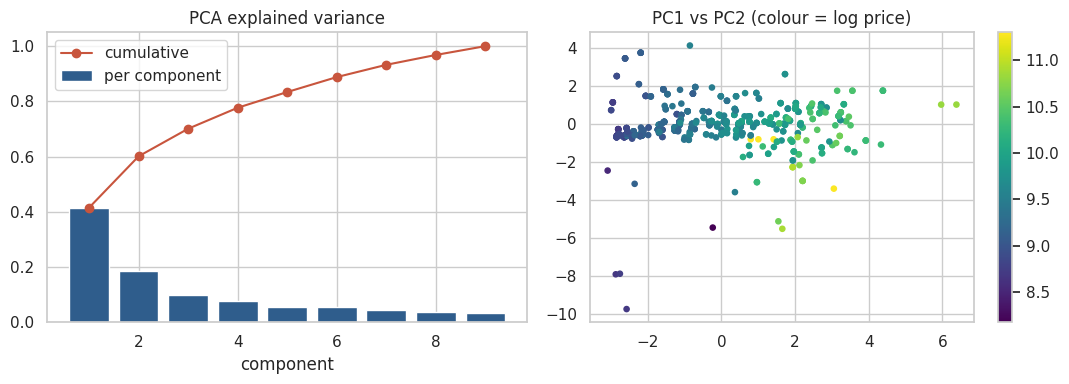

In [12]:
# PCA (dimensionality reduction) on standardised numeric features
Z = StandardScaler().fit_transform(num_imp)
pca = PCA().fit(Z)
RESULTS["pca_explained"] = pca.explained_variance_ratio_.round(3).tolist()
loadings = pd.DataFrame(pca.components_[:3].T, index=NUM, columns=["PC1", "PC2", "PC3"]).round(2)
RESULTS["pca_loadings"] = loadings.to_dict("index")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(range(1, len(NUM) + 1), pca.explained_variance_ratio_, color=PALETTE, label="per component")
ax[0].plot(range(1, len(NUM) + 1), np.cumsum(pca.explained_variance_ratio_), "o-", color="#C8553D", label="cumulative")
ax[0].set_title("PCA explained variance"); ax[0].set_xlabel("component"); ax[0].legend()
sc = ax[1].scatter(*PCA(2).fit_transform(Z).T, c=np.log(df[TARGET]), cmap="viridis", s=14)
ax[1].set_title("PC1 vs PC2 (colour = log price)"); plt.colorbar(sc, ax=ax[1])
savefig("06_pca.png")

## 5. Model building
Ridge (log-price), Decision Tree, Random Forest, Gradient Boosting (plus tuned and PCA variants), on a random split and an unseen-model split.

In [13]:
X = df[NUM + CAT]
y = df[TARGET].values
groups_all = df["ModelKey"].values   # all variants (RAM/storage/colour) of one phone share a group

pre_tree = ColumnTransformer([
    ("num", Pipeline([("imp", __import__("sklearn.impute", fromlist=["SimpleImputer"]).SimpleImputer(strategy="median"))]), NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])
pre_lin = ColumnTransformer([
    ("num", Pipeline([("imp", __import__("sklearn.impute", fromlist=["SimpleImputer"]).SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])

def feat_names(fitted_pre):
    return list(fitted_pre.get_feature_names_out())

candidates = {
    "Ridge (log-price)": (Pipeline([("pre", pre_lin), ("m", Ridge(alpha=3.0))]), True),
    "Decision Tree": (Pipeline([("pre", pre_tree), ("m", DecisionTreeRegressor(max_depth=8, min_samples_leaf=3, random_state=SEED))]), False),
    "Random Forest": (Pipeline([("pre", pre_tree), ("m", RandomForestRegressor(n_estimators=400, min_samples_leaf=2, n_jobs=-1, random_state=SEED))]), False),
    "Gradient Boosting": (Pipeline([("pre", pre_tree), ("m", GradientBoostingRegressor(n_estimators=400, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=SEED))]), False),
}

def metrics(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "R2": r2_score(y_true, y_pred),
            "MAPE_%": float(np.mean(np.abs((y_true - y_pred) / y_true)) * 100)}

def fit_predict(pipe, uselog, Xtr, ytr, Xte):
    p = __import__("sklearn.base", fromlist=["clone"]).clone(pipe)
    p.fit(Xtr, np.log(ytr) if uselog else ytr)
    pred = p.predict(Xte)
    return p, (np.exp(pred) if uselog else pred)

In [14]:
# Split A: plain random 80/20 split (what the brief literally asks for).
#          NOTE: optimistic - identical phones in different colours land in both sets.
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=SEED)
# Split B: leakage-safe split - whole phone models are held out (a "new launch" scenario).
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr_i, te_i = next(gss.split(X, y, groups_all))
XtrB, XteB, ytrB, yteB = X.iloc[tr_i], X.iloc[te_i], y[tr_i], y[te_i]
RESULTS["split_sizes"] = {"random": [len(Xtr), len(Xte)], "grouped": [len(XtrB), len(XteB)],
                          "grouped_test_models": int(len(set(groups_all[te_i])))}

rows = []
fitted_B = {}
preds_B = {}
for name, (pipe, uselog) in candidates.items():
    _, pa = fit_predict(pipe, uselog, Xtr, ytr, Xte)
    pB_model, pb = fit_predict(pipe, uselog, XtrB, ytrB, XteB)
    fitted_B[name] = pB_model; preds_B[name] = pb
    ma, mb = metrics(yte, pa), metrics(yteB, pb)
    rows.append({"Model": name, "Split": "Random 80/20", **ma})
    rows.append({"Model": name, "Split": "Unseen phone models", **mb})
res = pd.DataFrame(rows)

In [15]:
# Naive baseline for context
base_pred = np.full_like(yteB, np.median(ytrB), dtype=float)
bm = metrics(yteB, base_pred)
RESULTS["baseline_median_unseen"] = bm

# Cross-validated (GroupKFold) comparison for stability
gkf = GroupKFold(n_splits=5)
cv_rows = []
for name, (pipe, uselog) in candidates.items():
    maes, r2s = [], []
    for a, b in gkf.split(X, y, groups_all):
        _, p = fit_predict(pipe, uselog, X.iloc[a], y[a], X.iloc[b])
        maes.append(mean_absolute_error(y[b], p)); r2s.append(r2_score(y[b], p))
    cv_rows.append({"Model": name, "CV_MAE_mean": np.mean(maes), "CV_MAE_std": np.std(maes),
                    "CV_R2_mean": np.mean(r2s), "CV_R2_std": np.std(r2s)})
cv = pd.DataFrame(cv_rows)

In [16]:
# Light hyper-parameter tuning of the best-looking family (Gradient Boosting) with GroupKFold
gb_pipe = candidates["Gradient Boosting"][0]
grid = GridSearchCV(gb_pipe, {"m__n_estimators": [300, 600], "m__learning_rate": [0.03, 0.06],
                              "m__max_depth": [3, 4], "m__min_samples_leaf": [2, 5]},
                    cv=GroupKFold(n_splits=4), scoring="neg_mean_absolute_error", n_jobs=-1)
grid.fit(XtrB, ytrB, groups=groups_all[tr_i])
tuned = grid.best_estimator_
pt = tuned.predict(XteB)
res = pd.concat([res, pd.DataFrame([{"Model": "Gradient Boosting (tuned)", "Split": "Unseen phone models",
                                      **metrics(yteB, pt)}])], ignore_index=True)
RESULTS["gb_best_params"] = grid.best_params_
fitted_B["Gradient Boosting (tuned)"] = tuned; preds_B["Gradient Boosting (tuned)"] = pt

# PCA-based models: dimensionality reduction INSIDE the pipeline (scaled features -> PCA keeping 95% variance)
from sklearn.impute import SimpleImputer as _SI
def pca_pre():
    return ColumnTransformer([
        ("num", Pipeline([("imp", _SI(strategy="median")), ("sc", StandardScaler())]), NUM),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])
pca_models = {
    "PCA + Ridge (log-price)": (Pipeline([("pre", pca_pre()), ("pca", PCA(n_components=0.95, random_state=SEED)),
                                          ("m", Ridge(alpha=3.0))]), True),
    "PCA + Gradient Boosting": (Pipeline([("pre", pca_pre()), ("pca", PCA(n_components=0.95, random_state=SEED)),
                                          ("m", GradientBoostingRegressor(n_estimators=400, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=SEED))]), False)}
pca_cv_rows = []
for name, (pipe, uselog) in pca_models.items():
    _, pa = fit_predict(pipe, uselog, Xtr, ytr, Xte)
    fitted, pb = fit_predict(pipe, uselog, XtrB, ytrB, XteB)
    fitted_B[name] = fitted; preds_B[name] = pb
    res = pd.concat([res, pd.DataFrame([{"Model": name, "Split": "Random 80/20", **metrics(yte, pa)},
                                         {"Model": name, "Split": "Unseen phone models", **metrics(yteB, pb)}])], ignore_index=True)
    maes, r2s = [], []
    for a, b_ in gkf.split(X, y, groups_all):
        _, p_ = fit_predict(pipe, uselog, X.iloc[a], y[a], X.iloc[b_])
        maes.append(mean_absolute_error(y[b_], p_)); r2s.append(r2_score(y[b_], p_))
    pca_cv_rows.append({"Model": name, "CV_MAE_mean": np.mean(maes), "CV_MAE_std": np.std(maes),
                        "CV_R2_mean": np.mean(r2s), "CV_R2_std": np.std(r2s)})
cv = pd.concat([cv, pd.DataFrame(pca_cv_rows)], ignore_index=True)
RESULTS["pca_n_components"] = int(fitted_B["PCA + Ridge (log-price)"].named_steps["pca"].n_components_)
RESULTS["pca_input_dims"] = int(fitted_B["PCA + Ridge (log-price)"].named_steps["pre"].transform(XtrB).shape[1])

In [17]:
# Ablation: one-hot encode the Model name and Colour (as the brief suggests) - what happens?
ab_cat = CAT + ["Model", "Colour"]
X_ab = pd.concat([X, df[["Model", "Colour"]]], axis=1)
ab_pre = ColumnTransformer([("num", __import__("sklearn.impute", fromlist=["SimpleImputer"]).SimpleImputer(strategy="median"), NUM),
                            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ab_cat)])
ab = Pipeline([("pre", ab_pre), ("m", RandomForestRegressor(n_estimators=400, min_samples_leaf=2, n_jobs=-1, random_state=SEED))])
tr_r, te_r = train_test_split(np.arange(len(df)), test_size=0.2, random_state=SEED)
ab.fit(X_ab.iloc[tr_r], y[tr_r]); m_rand = metrics(y[te_r], ab.predict(X_ab.iloc[te_r]))
ab.fit(X_ab.iloc[tr_i], y[tr_i]); m_grp = metrics(y[te_i], ab.predict(X_ab.iloc[te_i]))
RESULTS["ablation_onehot_model_colour"] = {"random_split": m_rand, "unseen_models": m_grp}

## 6. Model evaluation
MAE, RMSE, R² and MAPE, plus grouped cross-validation.

                        Model                Split       MAE       RMSE     R2  MAPE_%
0           Ridge (log-price)         Random 80/20  4003.284  10171.012  0.499  15.048
1           Ridge (log-price)  Unseen phone models  2752.498   3483.514  0.810  18.134
2               Decision Tree         Random 80/20  2784.289   6296.579  0.808  11.573
3               Decision Tree  Unseen phone models  2947.367   4841.204  0.633  15.700
4               Random Forest         Random 80/20  2172.072   5771.786  0.839   8.760
5               Random Forest  Unseen phone models  2619.165   3564.947  0.801  15.530
6           Gradient Boosting         Random 80/20  1763.021   4784.393  0.889   7.170
7           Gradient Boosting  Unseen phone models  2164.652   3120.158  0.847  12.689
8   Gradient Boosting (tuned)  Unseen phone models  2328.045   3084.795  0.851  14.515
9     PCA + Ridge (log-price)         Random 80/20  4339.707  10443.267  0.472  17.391
10    PCA + Ridge (log-price)  Unseen phone

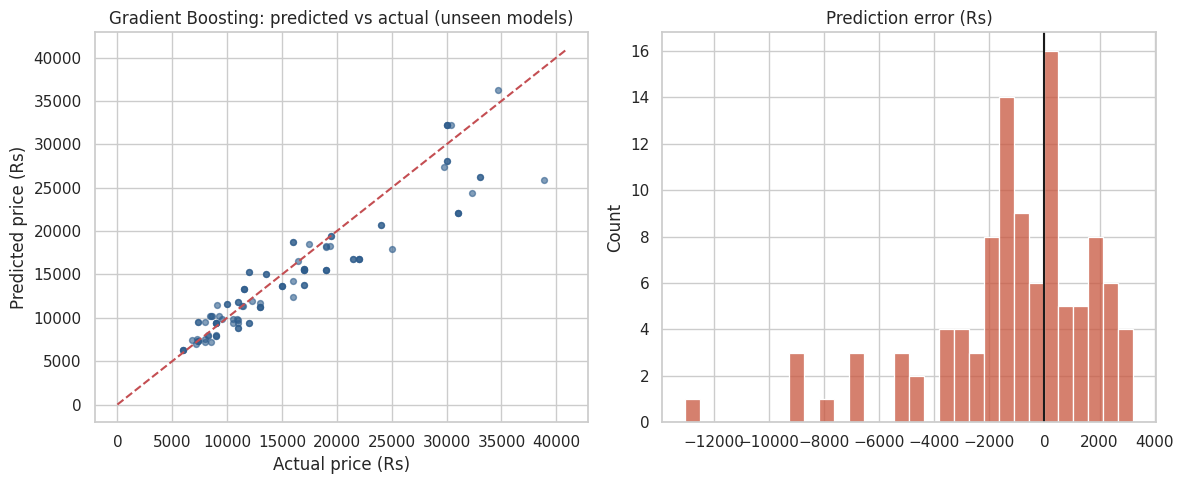

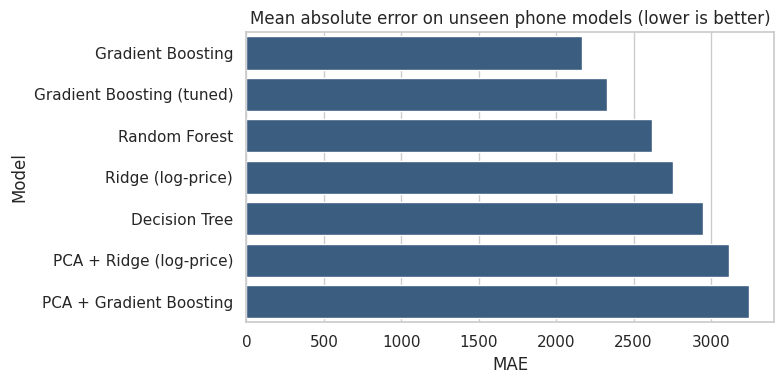

In [18]:
res.round(3).to_csv(DATA / "model_comparison.csv", index=False)
cv.round(3).to_csv(DATA / "cross_validation.csv", index=False)
RESULTS["model_comparison"] = res.round(3).to_dict("records")
RESULTS["cross_validation"] = cv.round(3).to_dict("records")
print(res.round(3).to_string()); print(cv.round(3).to_string())

best_name = res[res["Split"] == "Unseen phone models"].sort_values("MAE").iloc[0]["Model"]
RESULTS["best_model"] = best_name
best_pred = preds_B[best_name]
print("Best model on unseen phones:", best_name)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(yteB, best_pred, s=18, alpha=.6, color=PALETTE)
lim = [0, max(yteB.max(), best_pred.max()) * 1.05]
ax[0].plot(lim, lim, "r--"); ax[0].set_xlabel("Actual price (Rs)"); ax[0].set_ylabel("Predicted price (Rs)")
ax[0].set_title(f"{best_name}: predicted vs actual (unseen models)")
err = best_pred - yteB
sns.histplot(err, bins=30, color="#C8553D", ax=ax[1]); ax[1].axvline(0, color="k")
ax[1].set_title("Prediction error (Rs)")
savefig("07_predicted_vs_actual.png")

plot_df = res[res["Split"] == "Unseen phone models"].sort_values("MAE")
plt.figure(figsize=(8, 4))
sns.barplot(data=plot_df, y="Model", x="MAE", color=PALETTE)
plt.title("Mean absolute error on unseen phone models (lower is better)")
savefig("08_model_comparison.png")

## 7. Feature importance analysis
Impurity importance, permutation importance on unseen models, and grouped permutation for correlated feature bundles.

In [19]:
# (a) impurity-based importance from the tuned gradient boosting model, aggregated per source feature
pre_fit = tuned.named_steps["pre"]; model = tuned.named_steps["m"]
names = feat_names(pre_fit)
imp = pd.Series(model.feature_importances_, index=names)
def source(n):
    n = n.split("__", 1)[1]
    for c in CAT:
        if n.startswith(c + "_"):
            return c
    return n
imp_grouped = imp.groupby(source).sum().sort_values(ascending=False)

In [20]:
# (b) permutation importance on UNSEEN models (model-agnostic, grouped by original column)
perm = permutation_importance(tuned, XteB, yteB, scoring="neg_mean_absolute_error", n_repeats=30,
                              random_state=SEED, n_jobs=-1)
perm_s = pd.Series(perm.importances_mean, index=XteB.columns).sort_values(ascending=False)
perm_sd = pd.Series(perm.importances_std, index=XteB.columns)


# (d) GROUPED permutation: correlated features (RAM/storage/chipset/5G) split their credit in (b);
#     shuffling a related bundle together shows the bundle's true joint contribution.
def joint_perm(cols, reps=30):
    rng = np.random.default_rng(SEED); base_mae = mean_absolute_error(yteB, tuned.predict(XteB)); out = []
    for _ in range(reps):
        Xs = XteB.copy(); idx = rng.permutation(len(Xs))
        Xs[cols] = Xs[cols].values[idx]
        out.append(mean_absolute_error(yteB, tuned.predict(Xs)) - base_mae)
    return float(np.mean(out)), float(np.std(out))
bundles = {"Performance bundle (ChipTier+ChipFamily+RAM+Memory)": ["ChipTier", "ChipFamily", "RAM", "Memory"],
           "Memory + RAM only": ["Memory", "RAM"],
           "Cameras (Front+Rear)": ["FrontCamera", "RearCamera"],
           "Connectivity+Brand (Is5G+Brand)": ["Is5G", "Brand"]}
RESULTS["joint_permutation"] = {k: dict(zip(["mae_increase", "std"], joint_perm(v))) for k, v in bundles.items()}
print(RESULTS["joint_permutation"])

{'Performance bundle (ChipTier+ChipFamily+RAM+Memory)': {'mae_increase': 2841.8902197687626, 'std': 301.76102474581364}, 'Memory + RAM only': {'mae_increase': 717.0813358837496, 'std': 146.01776664261126}, 'Cameras (Front+Rear)': {'mae_increase': 915.8428117112543, 'std': 178.19008141259275}, 'Connectivity+Brand (Is5G+Brand)': {'mae_increase': 1217.6235848031115, 'std': 142.87271725467255}}


             GB_impurity  RF_impurity  Permutation_MAE_increase  \
ChipTier          0.4172       0.5050                 2041.8604   
Brand             0.0580       0.0568                  827.8007   
FrontCamera       0.1568       0.1279                  575.4586   
Is5G              0.0509       0.0077                  531.2437   
Battery           0.1787       0.1164                  514.7832   
Memory            0.0466       0.0519                  513.5634   
Height            0.0359       0.0350                  220.3884   
RAM               0.0125       0.0209                  153.8696   
ChipFamily        0.0215       0.0516                   98.8780   
RearCamera        0.0219       0.0265                   27.6369   
AILens            0.0001       0.0002                   18.5048   

             Spearman_with_price  MutualInfo  
ChipTier                  0.8085      0.7027  
Brand                        NaN      0.4063  
FrontCamera               0.7895      0.7093  
Is5G   

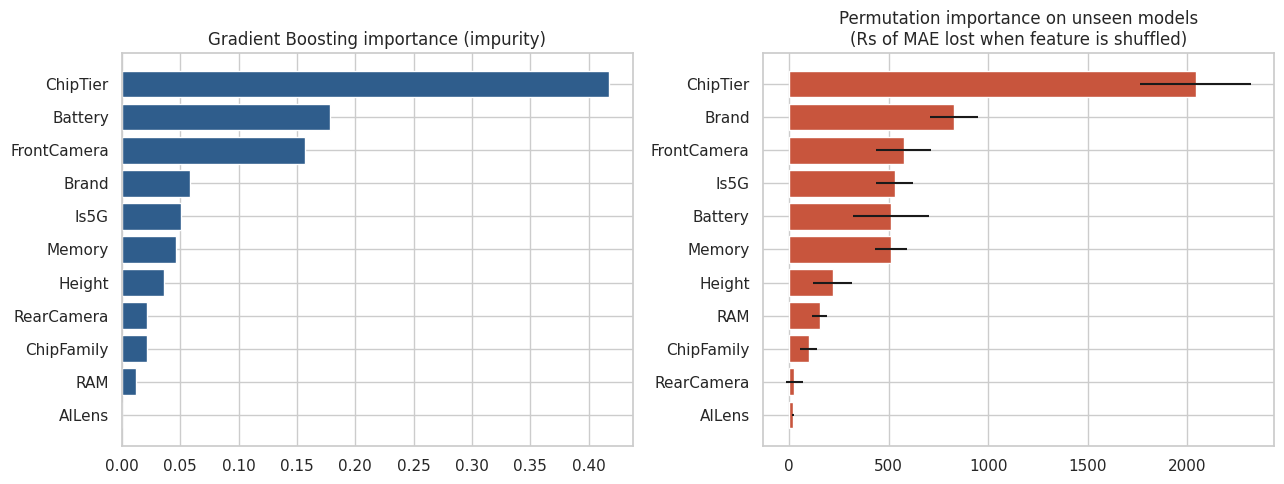

In [21]:
# (c) random-forest importance for cross-check
rf_fit = fitted_B["Random Forest"]
rf_imp = pd.Series(rf_fit.named_steps["m"].feature_importances_, index=feat_names(rf_fit.named_steps["pre"]))
rf_grouped = rf_imp.groupby(source).sum().sort_values(ascending=False)

summary = pd.DataFrame({"GB_impurity": imp_grouped, "RF_impurity": rf_grouped,
                        "Permutation_MAE_increase": perm_s,
                        "Spearman_with_price": corr["spearman"],
                        "MutualInfo": fs["mutual_info"]})
summary = summary.sort_values("Permutation_MAE_increase", ascending=False)
summary.round(4).to_csv(DATA / "feature_importance_summary.csv")
RESULTS["importance"] = summary.round(4).to_dict("index")
print(summary.round(4))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
g = imp_grouped.iloc[::-1]
ax[0].barh(g.index, g.values, color=PALETTE); ax[0].set_title("Gradient Boosting importance (impurity)")
p = perm_s.iloc[::-1]
ax[1].barh(p.index, p.values, xerr=perm_sd[p.index].values, color="#C8553D")
ax[1].set_title("Permutation importance on unseen models\n(Rs of MAE lost when feature is shuffled)")
savefig("09_feature_importance.png")

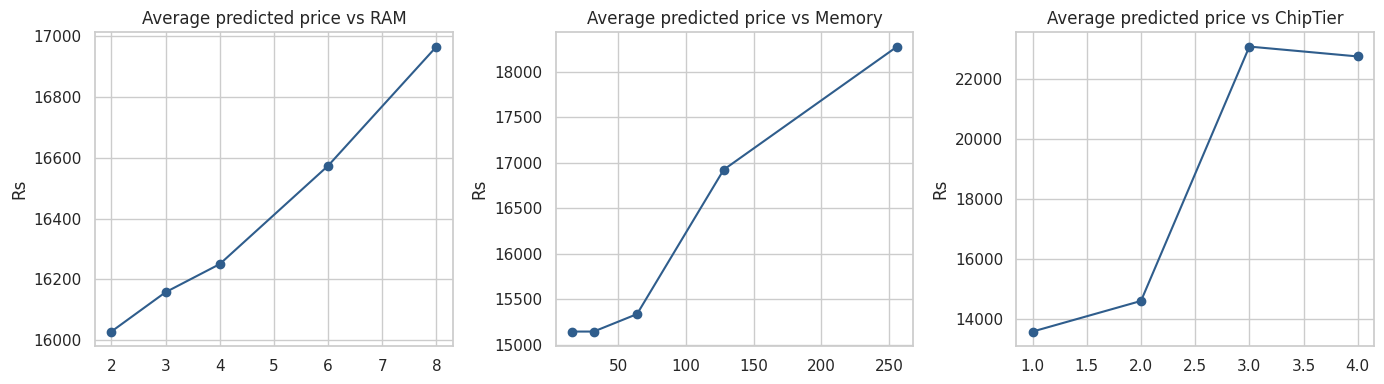

Done.


In [22]:
# Partial-dependence style view: average prediction by RAM / storage / chip tier
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, col in zip(ax, ["RAM", "Memory", "ChipTier"]):
    Xp = X.copy(); vals = sorted(Xp[col].dropna().unique()); out = []
    for v in vals:
        Xp[col] = v; out.append(tuned.predict(Xp).mean())
    a.plot(vals, out, "o-", color=PALETTE); a.set_title(f"Average predicted price vs {col}")
    a.set_ylabel("Rs")
savefig("10_partial_dependence.png")

# Price premium per feature level (descriptive, from cleaned data)
RESULTS["median_price_by_ram"] = df.groupby("RAM")[TARGET].median().to_dict()
RESULTS["median_price_by_storage"] = df.groupby("Memory")[TARGET].median().to_dict()
RESULTS["median_price_by_tier"] = df.groupby("ChipTier")[TARGET].median().to_dict()
RESULTS["median_price_by_brand"] = df.groupby("Brand")[TARGET].median().sort_values(ascending=False).to_dict()
RESULTS["median_price_5g"] = df.groupby("Is5G")[TARGET].median().to_dict()
RESULTS["median_price_ailens"] = df.groupby("AILens")[TARGET].median().to_dict()

txt = json.dumps(RESULTS, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
txt = re.sub(r"\bNaN\b", "null", txt)          # keep results.json valid JSON
(ROOT / "results.json").write_text(txt)
print("Done.")

## 8. Recommendations
See the report (`Mobile_Price_Prediction_Report.docx`) for the full recommendations. In short: price on **performance tier** (chipset, RAM, storage) first, then adjust for **5G and brand**; treat front-camera megapixels as a segment signal; do not price on **AI Lens**, **colour** or **battery size**.